# North Batten SC-PaCMAP results

This compact notebook follows the current North Batten benchmark style: 30 algorithm seeds, full-population embeddings, K-means at the known lithology count $K=15$, and labels used only for evaluation and plotting.

The notebook keeps the essential data walk-through, one-seed embedding view, three evaluation range plots, the $K=15$ trade-off cloud, a 10-seed lambda-cap showcase, and the cross-hole leave-one-out continuity check. No exports are written.

In [5]:
from __future__ import annotations
import os, sys
from pathlib import Path

# Keep an already imported kernel's Numba pool size; use one active thread.
# On a fresh kernel, configure the pool before numerical imports.
os.environ['NUMBA_NUM_THREADS'] = str(sys.modules['numba'].config.NUMBA_NUM_THREADS) if 'numba' in sys.modules else '1'
import matplotlib.pyplot as plt
import numba, numpy as np, pandas as pd, seaborn as sns
numba.set_num_threads(1)
import pacmap, umap
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False})
def find_root(start=Path.cwd()):
    for candidate in (start.resolve(),*start.resolve().parents):
        if (candidate/'code'/'sc_pacmap'/'sc_pacmap.py').is_file(): return candidate
        nested=candidate/'sc-pacmap-reproducibility'
        if (nested/'code'/'sc_pacmap'/'sc_pacmap.py').is_file(): return nested
    raise FileNotFoundError('Repository root not found')
ROOT=find_root()
for folder in (ROOT/'code'/'sc_pacmap',ROOT/'code'/'spasne'):
    sys.path.insert(0,str(folder)) if str(folder) not in sys.path else None
from sc_pacmap import PaCMAPSettings, SCPaCMAPConfig, run_legacy_sc_pacmap, run_sc_pacmap
from spasne_adapter import python_spasne
from notebook_support import localmap_seed
SEEDS=tuple(range(30)); SENSITIVITY_SEEDS=tuple(range(10)); N_NEIGHBORS=10; K_REFERENCE=15
data=pd.read_csv(ROOT/'data'/'processed'/'north_batten_sc_pacmap_ready.csv')
FEATURES=[c for c in data.columns if c.endswith(('_PPM','_PCT'))]
coords=data[['x','y','z']].to_numpy(float); truth=data.label_id.to_numpy(int)
features=StandardScaler().fit_transform(data[FEATURES]).astype(np.float32); xyz=StandardScaler().fit_transform(coords); features_xyz=np.column_stack([features,xyz])
tss=float(np.sum((features-features.mean(0,keepdims=True))**2)); spatial_neighbors=NearestNeighbors(n_neighbors=N_NEIGHBORS+1,n_jobs=1).fit(coords).kneighbors(coords,return_distance=False)[:,1:]
settings_base=dict(n_components=2,n_neighbors=N_NEIGHBORS,mn_ratio=.5,fp_ratio=2.,learning_rate=1.,num_iters=(100,100,250),knn_backend='faiss',verbose=False)
METHODS=['UMAP + XYZ','PaCMAP + XYZ','LocalMAP + XYZ','PaCMAP feature-only','SC-PaCMAP replacement','SC-PaCMAP full graph','SpaSNE']
print(f'{len(data)} intervals | {len(FEATURES)} features | {data.group_id.nunique()} drillholes | K={K_REFERENCE}')
K_VALUES = range(2, 16)
COLORS = dict(zip(METHODS, ['#D55E00', '#56B4E9', '#009E73', '#7A5195', '#E15759', '#E60049', '#D4A900']))
MARKERS = dict(zip(METHODS, ['o', '^', 'v', 'P', 'h', '*', 'X']))

3222 intervals | 46 features | 22 drillholes | K=15


## Data walk-through

Lithology is evaluation-only. The drillhole field is retained for the cross-hole continuity check, while standardized geochemistry and optional standardized XYZ are the embedding inputs.

,label_id,label_lithology,intervals
0,0,BXZN - Breccia Zone,27
1,1,LSR - Saprock,32
2,2,SAN - Arenite,24
3,3,SCH - Carbonaceous Shale,47
4,4,SDE - Dolarenite; coarse grained dolostone,28
5,5,SDH - Dolomitic Shale,201
6,6,SDL - Laminated Dolomite,20
7,7,SDM - Stromatolitic Dolomite,33
8,8,SDO - Dolomite,299
9,9,SIH - Interbedded siltstone/shale,65


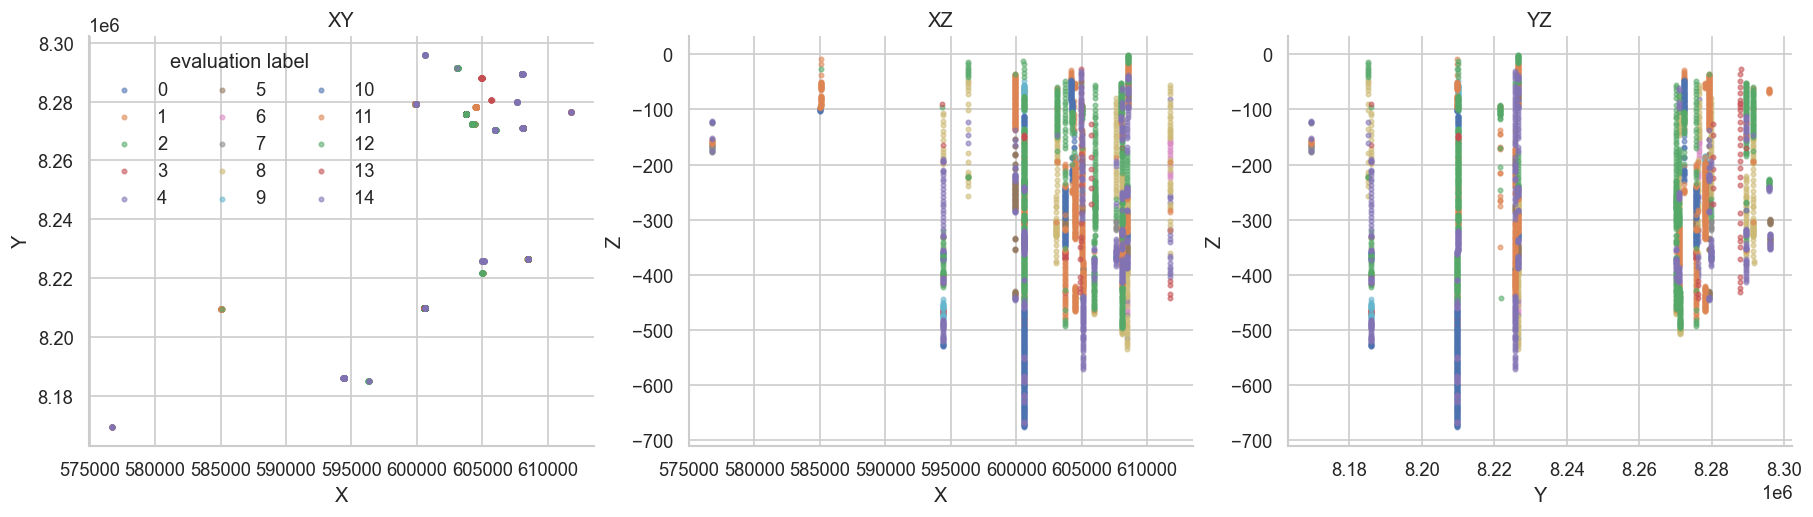

In [6]:
from IPython.display import display

display(data.groupby(['label_id','label_lithology'],observed=True).size().rename('intervals').reset_index())
fig,axes=plt.subplots(1,3,figsize=(15,4.2),constrained_layout=True)
for ax,pair in zip(axes,[('x','y'),('x','z'),('y','z')]):
    for label in sorted(data.label_id.unique()):
        mask=truth==label; ax.scatter(data.loc[mask,pair[0]],data.loc[mask,pair[1]],s=7,alpha=.55,label=str(label))
    ax.set(xlabel=pair[0].upper(),ylabel=pair[1].upper(),title=f'{pair[0].upper()}{pair[1].upper()}')
axes[0].legend(frameon=False,ncol=3,title='evaluation label'); plt.show()

## One seed: embeddings and K=15 evaluation

Each panel colors the raw 2-D embedding by the evaluation-only true label. K-means
still evaluates the same embedding at $K=15$ for the result table below. Cluster IDs
do not correspond between methods, and ground-truth labels are used only for plotting
and the ARI in the result table.

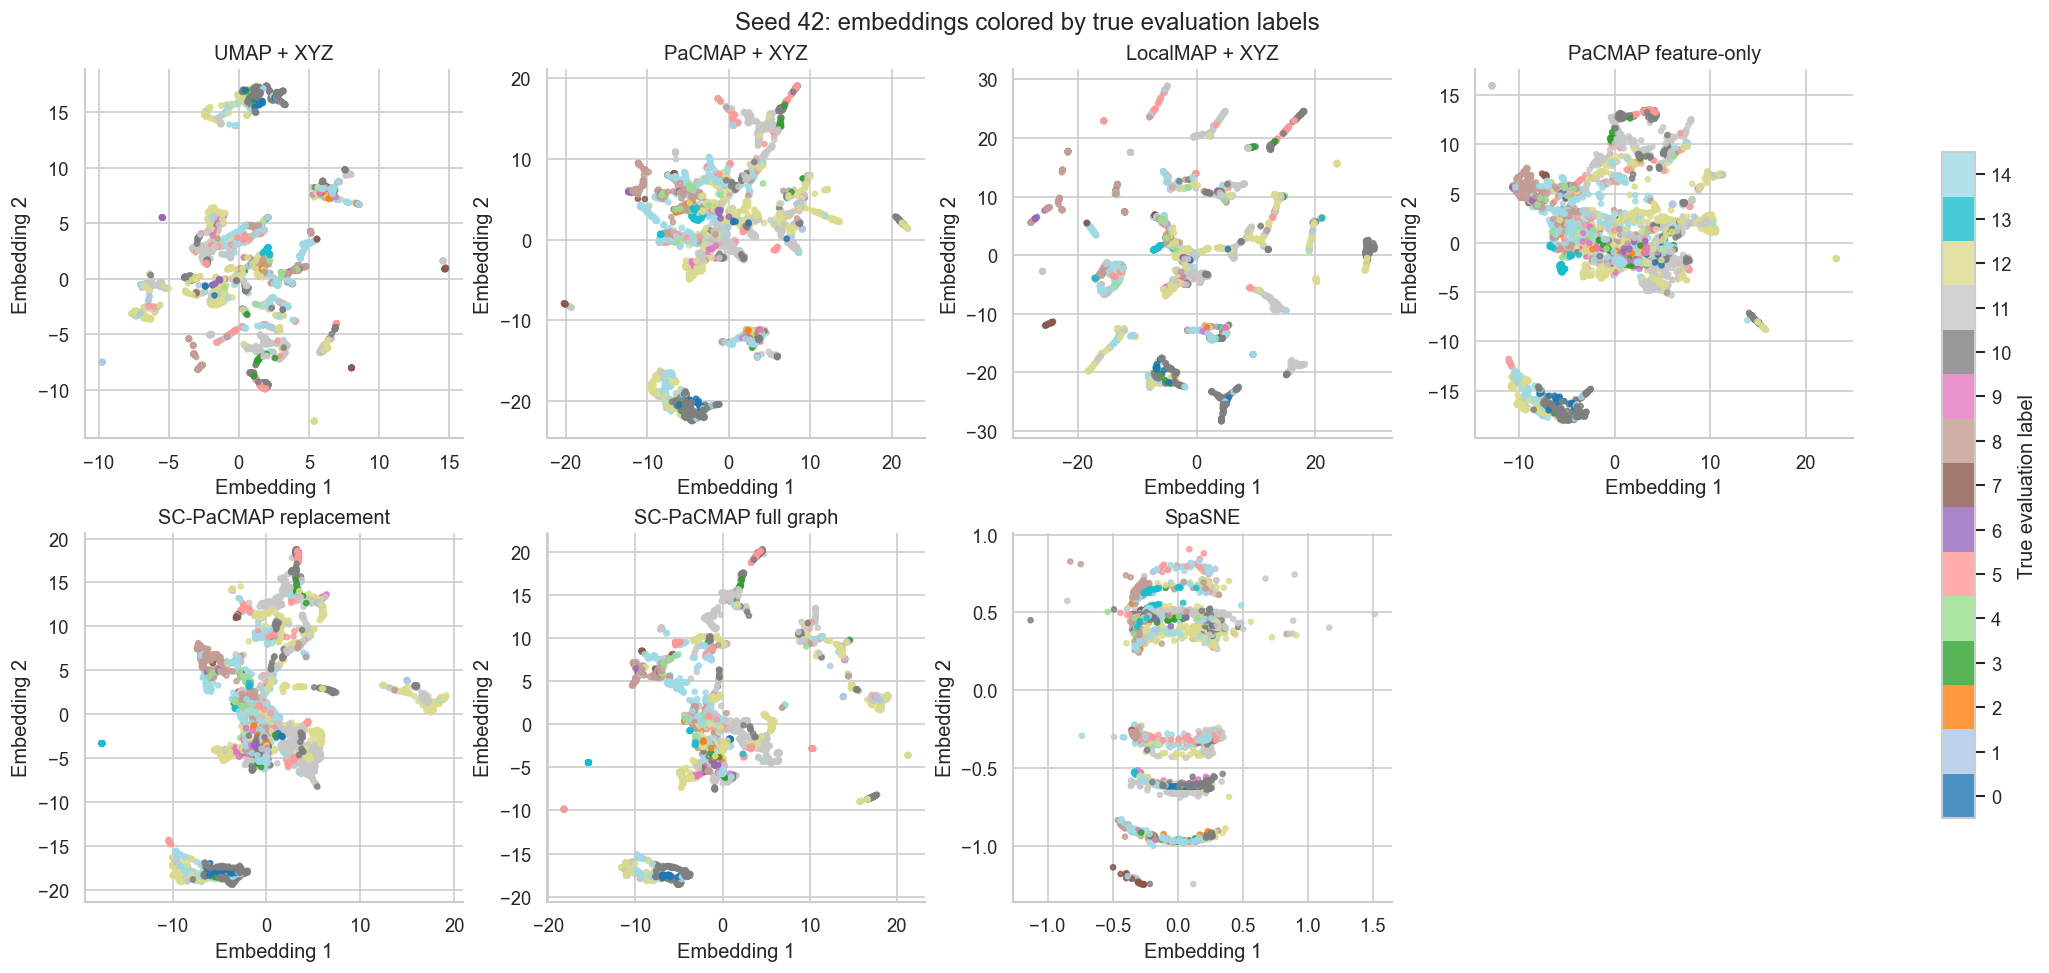

,method,K,H_per_sample,WCSS_TSS,ARI
0,UMAP + XYZ,15,0.3087,0.6716,0.1212
1,PaCMAP + XYZ,15,0.3635,0.6443,0.1054
2,LocalMAP + XYZ,15,0.3367,0.6891,0.1036
3,PaCMAP feature-only,15,0.5690,0.5854,0.1246
4,SC-PaCMAP replacement,15,0.2558,0.6444,0.1181
5,SC-PaCMAP full graph,15,0.2301,0.6357,0.1229
6,SpaSNE,15,0.4064,0.6641,0.1092


Automatic spatial-strength lambda: 0.511


In [7]:
def fit_embeddings(seed, feature_values=features, coordinate_values=coords):
    numba.set_num_threads(1)
    features_with_coordinates = np.column_stack([feature_values, StandardScaler().fit_transform(coordinate_values)])
    settings=PaCMAPSettings(random_state=seed,**settings_base); args={'n_components':2,'n_neighbors':N_NEIGHBORS,'MN_ratio':.5,'FP_ratio':2.,'distance':'euclidean','lr':1.,'num_iters':(100,100,250),'apply_pca':True,'random_state':seed,'save_tree':False,'knn_backend':'faiss'}; out={}
    out['UMAP + XYZ']=umap.UMAP(n_neighbors=N_NEIGHBORS,n_components=2,metric='euclidean',learning_rate=1.,random_state=seed,n_jobs=1).fit_transform(features_with_coordinates)
    out['PaCMAP + XYZ']=pacmap.PaCMAP(**args).fit_transform(features_with_coordinates,init='pca',save_pairs=False)
    with localmap_seed(seed):
        out['LocalMAP + XYZ']=pacmap.LocalMAP(**{**args,'low_dist_thres':10}).fit_transform(np.ascontiguousarray(features_with_coordinates, dtype=np.float64),init='pca',save_pairs=False)
    out['PaCMAP feature-only']=pacmap.PaCMAP(**args).fit_transform(feature_values,init='pca',save_pairs=False)
    r,_=run_legacy_sc_pacmap(feature_values,coordinate_values,settings); out['SC-PaCMAP replacement']=r.embedding
    r,d=run_sc_pacmap(feature_values,coordinate_values,settings); out['SC-PaCMAP full graph']=r.embedding
    out['SpaSNE']=python_spasne(feature_values,coordinate_values,random_state=seed,alpha=10.,beta=5.,exaggeration=4,perplexity=50,theta=.5,max_iter=1000,use_pca=True,spasne_dir=ROOT/'code'/'spasne'/'spasne_original')
    return out,d


def entropy(labels, neighbors=spatial_neighbors):
    total = 0.
    for n in neighbors:
        counts = np.bincount(labels[n])
        p = counts[counts > 0] / neighbors.shape[1]
        total -= float(np.sum(p * np.log(p)))
    return total / len(labels)


def wcss(labels, k=K_REFERENCE, feature_values=features, total_ss=tss):
    centers = np.vstack([feature_values[labels == j].mean(0) for j in range(k)])
    return float(np.sum((feature_values - centers[labels])**2)) / total_ss


def evaluate(labels, k, feature_values=features, neighbors=spatial_neighbors,
             label_truth=truth, total_ss=tss):
    return {'H_per_sample': entropy(labels, neighbors),
            'WCSS_TSS': wcss(labels, k, feature_values, total_ss),
            'ARI': adjusted_rand_score(label_truth, labels)}

one_seed_embeddings, one_seed_diag = fit_embeddings(42)
# Convert stored embeddings to float64 before K-means evaluation.
one_seed_embeddings = {m: np.asarray(y, dtype=np.float64) for m, y in one_seed_embeddings.items()}
one_seed_rows = []
fig, axes = plt.subplots(2, 4, figsize=(17, 8), constrained_layout=True)
true_label_cmap = plt.get_cmap('tab20', len(np.unique(truth)))
for ax, method in zip(axes.flat, METHODS):
    embedding = one_seed_embeddings[method]
    cluster_labels = KMeans(n_clusters=K_REFERENCE, init='k-means++', n_init=20,
                    random_state=1000 + K_REFERENCE).fit_predict(embedding)
    one_seed_rows.append({'method': method, 'K': K_REFERENCE, **evaluate(cluster_labels, K_REFERENCE)})
    points = ax.scatter(embedding[:, 0], embedding[:, 1], c=truth,
                        cmap=true_label_cmap, vmin=truth.min() - .5, vmax=truth.max() + .5, s=9, alpha=.8)
    ax.set(title=method, xlabel='Embedding 1', ylabel='Embedding 2')
axes.flat[-1].set_visible(False)
fig.colorbar(points, ax=list(axes.flat[:-1]), ticks=sorted(np.unique(truth)),
             label='True evaluation label', shrink=.8)
fig.suptitle('Seed 42: embeddings colored by true evaluation labels')
plt.show()
one_seed_results = pd.DataFrame(one_seed_rows)
display(one_seed_results.round(4))
print(f'Automatic spatial-strength lambda: {one_seed_diag.spatial_strength_lambda:.3f}')

## Thirty-seed evaluation curves with stability ranges

The three panels use the old notebooks' raw metrics: mean windowed entropy $H/N$
and feature-space WCSS/TSS (lower is better), and adjusted Rand index (higher is better).
K-means uses the raw embedding with 20 initializations. The vertical line marks the
reference K. Shading shows observed min-max ranges, not confidence intervals.

All 30 algorithm seeds run on the same full dataset. Lines show across-seed
medians and bands show the seed range at each K.

Completed algorithm seed 0


Completed algorithm seed 1


Completed algorithm seed 2


Completed algorithm seed 3


Completed algorithm seed 4


...

Completed algorithm seed 25


Completed algorithm seed 26


Completed algorithm seed 27


Completed algorithm seed 28


Completed algorithm seed 29


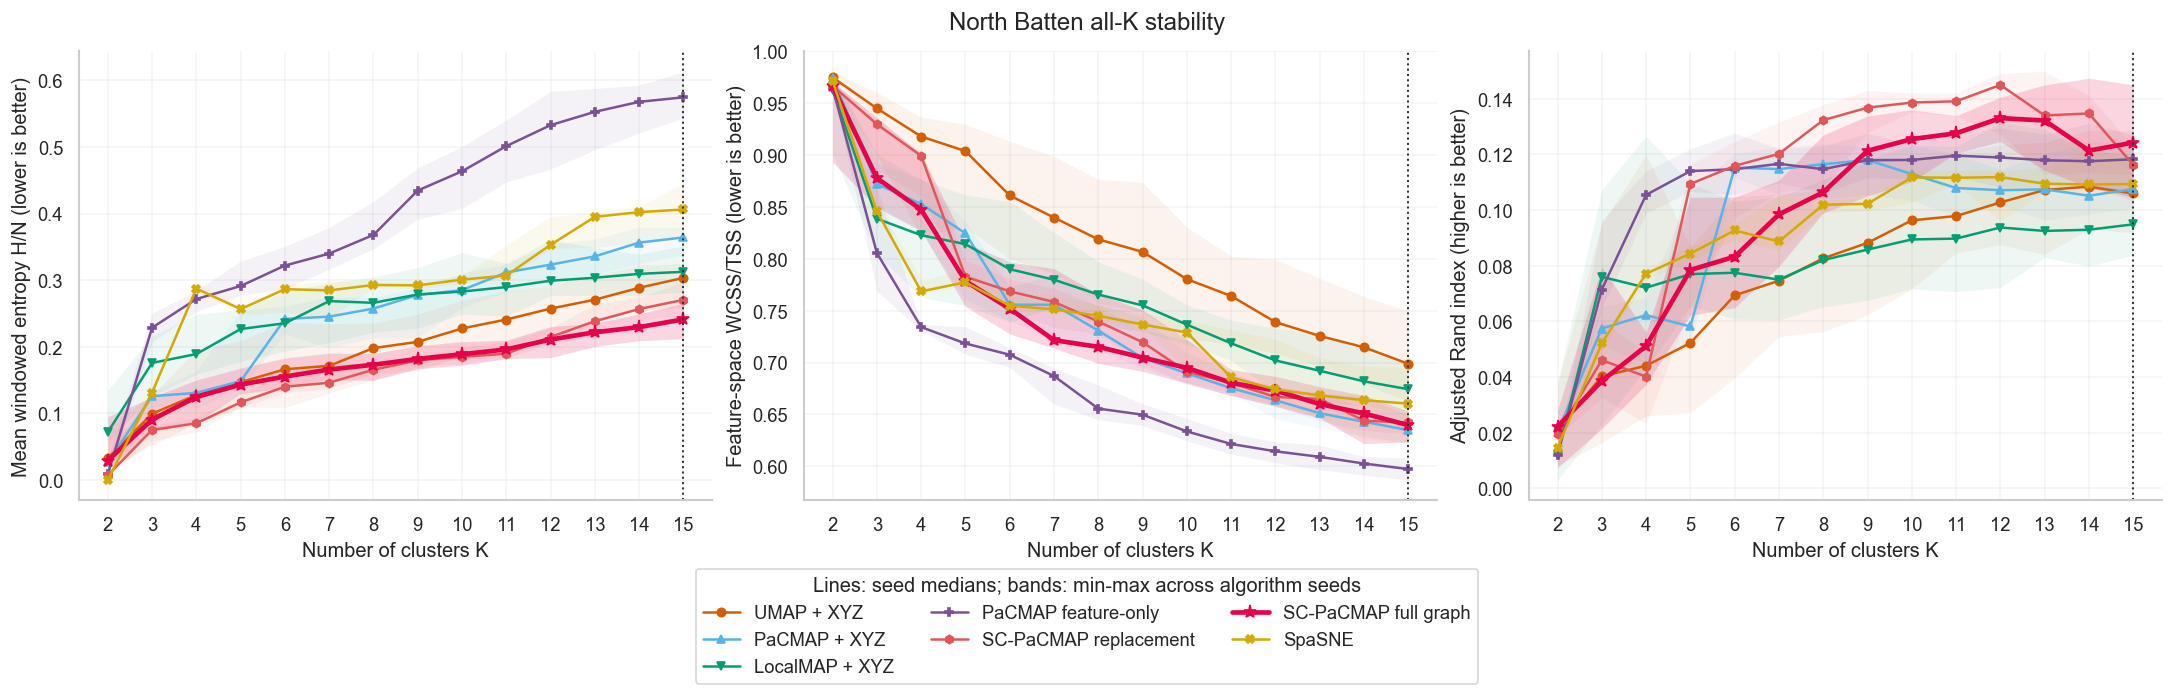

In [8]:
rows = []
for seed in SEEDS:
    embeddings = one_seed_embeddings if seed == 42 else fit_embeddings(seed)[0]
    for method in METHODS:
        for k in K_VALUES:
            labels = KMeans(n_clusters=k, init='k-means++', n_init=20,
                            random_state=1000 + k).fit_predict(embeddings[method])
            rows.append({'seed': seed, 'method': method, 'K': k, **evaluate(labels, k)})
    print(f'Completed algorithm seed {seed}', flush=True)
results = pd.DataFrame(rows)
range_results = results

metric_specs = [('H_per_sample', 'Mean windowed entropy H/N', 'lower is better'),
                ('WCSS_TSS', 'Feature-space WCSS/TSS', 'lower is better'),
                ('ARI', 'Adjusted Rand index', 'higher is better')]
fig, axes = plt.subplots(1, 3, figsize=(18, 5.7), constrained_layout=True)
for ax, (metric, ylabel, direction) in zip(axes, metric_specs):
    for method in METHODS:
        summary = range_results[range_results.method == method].groupby('K')[metric].agg(['median', 'min', 'max'])
        primary = method == 'SC-PaCMAP full graph'
        ax.fill_between(summary.index, summary['min'], summary['max'], color=COLORS[method],
                        alpha=.16 if primary else .07, linewidth=0)
        ax.plot(summary.index, summary['median'], color=COLORS[method], marker=MARKERS[method],
                linewidth=2.8 if primary else 1.5, markersize=8 if primary else 5, label=method)
    ax.axvline(K_REFERENCE, color='#333333', ls=':', lw=1.2)
    ax.set(xlabel='Number of clusters K', ylabel=f'{ylabel} ({direction})', xticks=list(K_VALUES))
    ax.grid(alpha=.2)
fig.suptitle('North Batten all-K stability')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=3,
           title='Lines: seed medians; bands: min-max across algorithm seeds')
plt.show()

## Trade-off cloud at $K=15$

Each faint point is one algorithm-seed run.
The large outlined marker is the across-seed median.
The axes retain the old raw entropy and WCSS/TSS scales: lower-left is better jointly.

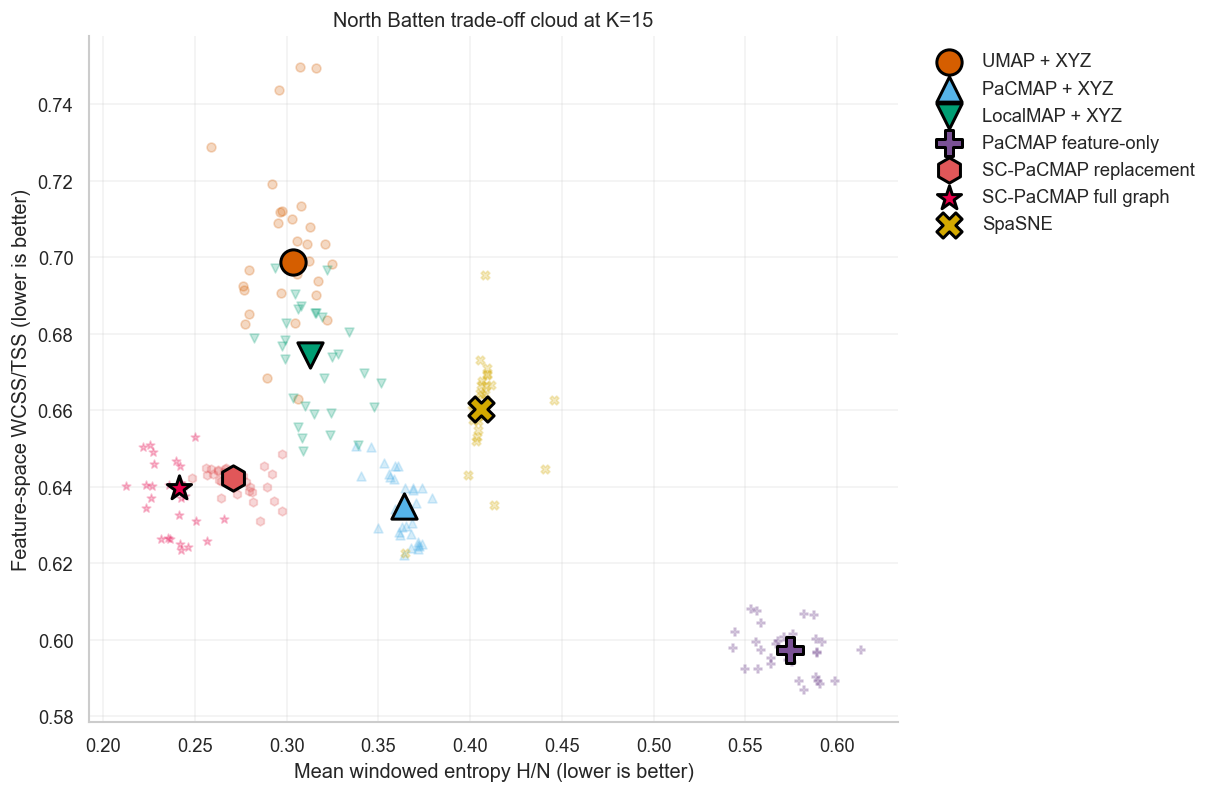

In [9]:
cloud = results[results.K == K_REFERENCE]
cloud_medians = range_results[range_results.K == K_REFERENCE].groupby('method')[['H_per_sample', 'WCSS_TSS']].median()
fig, ax = plt.subplots(figsize=(10, 6.5), constrained_layout=True)
for method in METHODS:
    part = cloud[cloud.method == method]
    ax.scatter(part.H_per_sample, part.WCSS_TSS, color=COLORS[method],
               marker=MARKERS[method], s=28, alpha=.24)
    median = cloud_medians.loc[method]
    ax.scatter(median.H_per_sample, median.WCSS_TSS, color=COLORS[method], marker=MARKERS[method],
               s=230, edgecolor='black', linewidth=1.8, label=method, zorder=4)
ax.set(xlabel='Mean windowed entropy H/N (lower is better)',
       ylabel='Feature-space WCSS/TSS (lower is better)', title=f'North Batten trade-off cloud at K={K_REFERENCE}')
ax.grid(alpha=.25)
ax.legend(frameon=False, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

## Lambda-cap sensitivity at $K=15$

Ten algorithm seeds sweep `SCPaCMAPConfig(max_target_share=...)` on the fixed
full dataset. This parameter caps both the automatically inferred lambda used
in the share calculation and the final Phase-3 spatial-attraction share; it does
not replace lambda with a manually fixed value. The default benchmark remains at 0.95.
The dashed line marks the data-derived automatic lambda for reference.

Lines show seed medians; shading shows min-max seed ranges. Here the two evaluation
scores are percentages (higher is better): spatial contiguity is
$100(1-(H/N)/\log K)$ and multivariate delineation is $100(1-\mathrm{WCSS}/\mathrm{TSS})$.

Completed sensitivity seed 0
Completed sensitivity seed 1
Completed sensitivity seed 2
Completed sensitivity seed 3
Completed sensitivity seed 4
Completed sensitivity seed 5
Completed sensitivity seed 6
Completed sensitivity seed 7
Completed sensitivity seed 8
Completed sensitivity seed 9


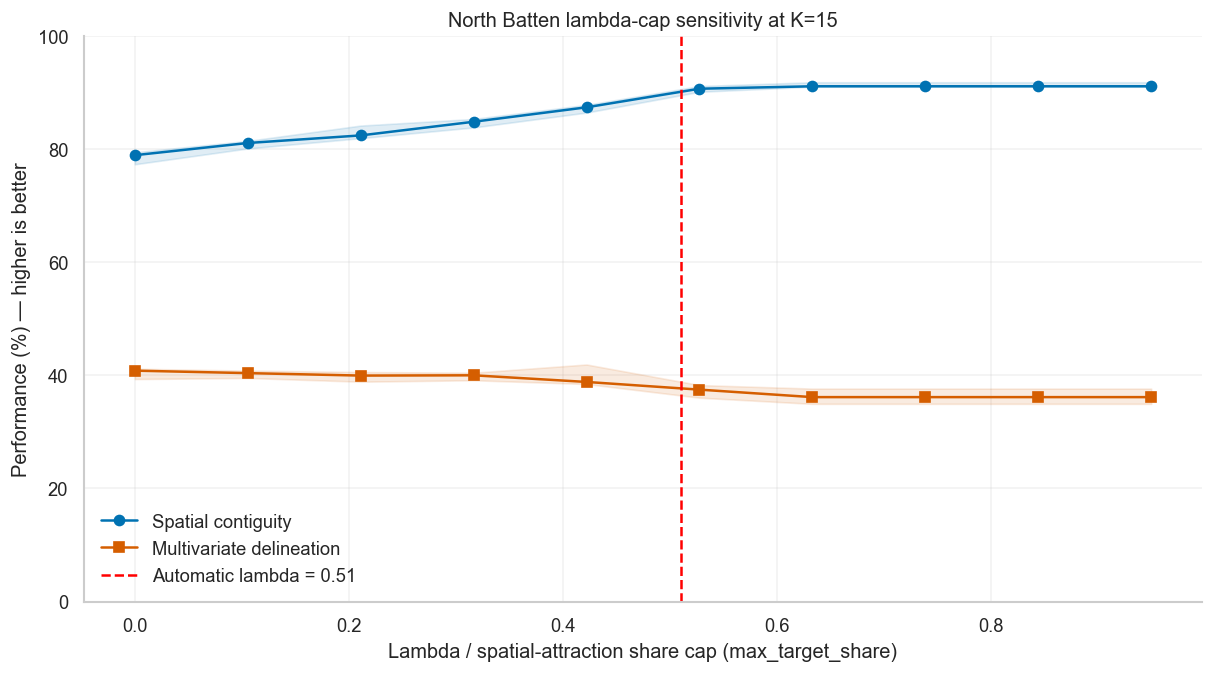

In [10]:
lambda_caps = np.linspace(0., .95, 10)
lambda_rows = []
for seed in SENSITIVITY_SEEDS:
    settings = PaCMAPSettings(random_state=seed, **settings_base)
    for cap in lambda_caps:
        result, diag = run_sc_pacmap(features, coords, settings,
                                    config=SCPaCMAPConfig(max_target_share=float(cap)))
        labels = KMeans(n_clusters=K_REFERENCE, init='k-means++', n_init=20,
                        random_state=1000 + K_REFERENCE).fit_predict(result.embedding)
        metrics = evaluate(labels, K_REFERENCE)
        lambda_rows.append({'seed': seed, 'lambda_cap': cap,
                            'automatic_lambda': diag.spatial_strength_lambda,
                            'target_share': diag.automatic_target_share,
                            'spatial': 100 * (1 - metrics['H_per_sample'] / np.log(K_REFERENCE)),
                            'multivariate': 100 * (1 - metrics['WCSS_TSS'])})
    print(f'Completed sensitivity seed {seed}', flush=True)
lambda_results = pd.DataFrame(lambda_rows)
automatic_lambda = float(lambda_results.automatic_lambda.median())
fig, ax = plt.subplots(figsize=(10, 5.5), constrained_layout=True)
for metric, label, color, marker in [
    ('spatial', 'Spatial contiguity', '#0072B2', 'o'),
    ('multivariate', 'Multivariate delineation', '#D55E00', 's'),
]:
    summary = lambda_results.groupby('lambda_cap')[metric].agg(['median', 'min', 'max'])
    ax.fill_between(summary.index, summary['min'], summary['max'], color=color, alpha=.12)
    ax.plot(summary.index, summary['median'], color=color, marker=marker, label=label)
ax.axvline(automatic_lambda, color='red', ls='--', label=f'Automatic lambda = {automatic_lambda:.2f}')
ax.set(xlabel='Lambda / spatial-attraction share cap (max_target_share)',
       ylabel='Performance (%) — higher is better', ylim=(0, 100),
       title=f'North Batten lambda-cap sensitivity at K={K_REFERENCE}')
ax.legend(frameon=False)
ax.grid(alpha=.25)
plt.show()

## Cross-hole leave-one-out continuity

Each interval $i$ is evaluated using only spatial neighbours from different drillholes, so same-hole intervals cannot make continuity look better. The focal interval is excluded. This is a continuity diagnostic, not a new embedding fit.

,median,min,max
method,,,
LocalMAP + XYZ,91.81,87.94,92.82
PaCMAP + XYZ,89.07,83.75,90.35
PaCMAP feature-only,77.51,75.89,80.35
SC-PaCMAP full graph,92.59,90.45,93.49
SC-PaCMAP replacement,87.59,86.32,94.15
SpaSNE,86.21,84.87,86.43
UMAP + XYZ,86.16,84.34,88.71


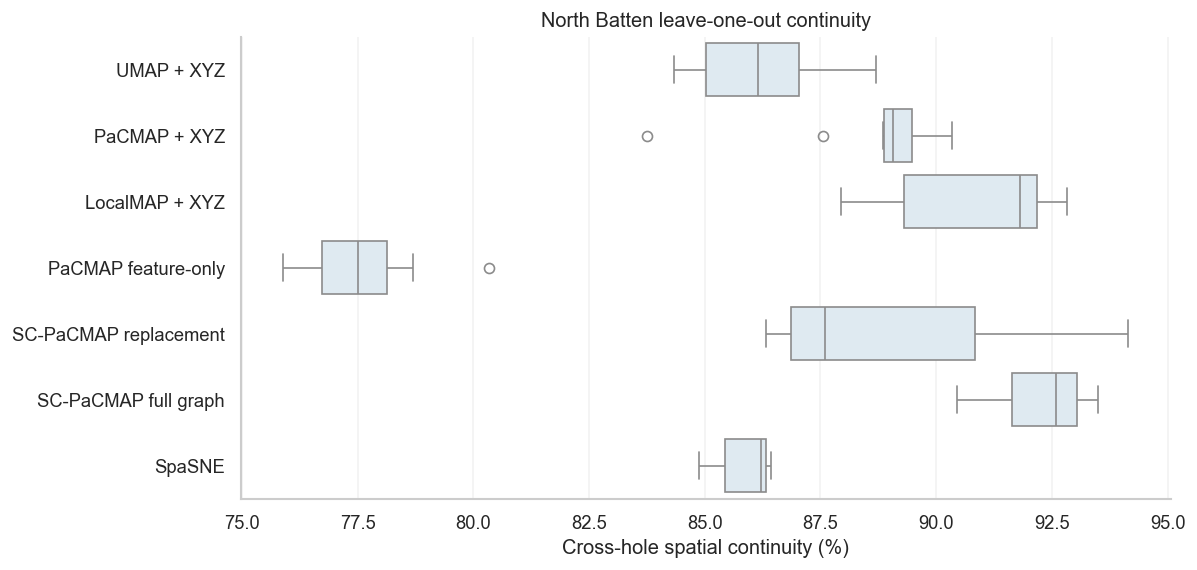

,primary,comparator,paired_seeds,median_difference,primary_wins,ties,wilcoxon_statistic,p_greater,holm_p
0,SC-PaCMAP full graph,UMAP + XYZ,10,6.1365,10,0,55.0,0.0010,0.0059
1,SC-PaCMAP full graph,PaCMAP + XYZ,10,3.4280,10,0,55.0,0.0010,0.0059
2,SC-PaCMAP full graph,PaCMAP feature-only,10,14.9153,10,0,55.0,0.0010,0.0059
3,SC-PaCMAP full graph,SpaSNE,10,6.7136,10,0,55.0,0.0010,0.0059
4,SC-PaCMAP full graph,SC-PaCMAP replacement,10,4.2596,8,0,49.0,0.0137,0.0273
5,SC-PaCMAP full graph,LocalMAP + XYZ,10,0.8584,7,0,44.0,0.0527,0.0527


One-sided paired Wilcoxon tests whether SC-PaCMAP full graph has higher cross-hole continuity than each comparator; Holm-adjusted alpha = 0.05.
Statistically higher than every comparator: False


In [12]:
from scipy.stats import wilcoxon


def paired_wilcoxon_table(frame, value_column, primary_method='SC-PaCMAP full graph'):
    rows = []
    comparator_methods = [method for method in METHODS if method != primary_method]
    for comparator in comparator_methods:
        paired = frame.pivot(index='seed', columns='method', values=value_column).dropna()
        differences = paired[primary_method] - paired[comparator]
        if np.allclose(differences, 0.0):
            statistic, p_value = 0.0, 1.0
        else:
            test = wilcoxon(
                differences,
                alternative='greater',
                zero_method='wilcox',
                method='auto',
            )
            statistic, p_value = float(test.statistic), float(test.pvalue)
        rows.append({
            'primary': primary_method,
            'comparator': comparator,
            'paired_seeds': len(differences),
            'median_difference': float(np.median(differences)),
            'primary_wins': int(np.sum(differences > 0)),
            'ties': int(np.sum(differences == 0)),
            'wilcoxon_statistic': statistic,
            'p_greater': p_value,
        })
    results = pd.DataFrame(rows).sort_values('p_greater').reset_index(drop=True)
    running_maximum = 0.0
    adjusted = []
    for rank, p_value in enumerate(results['p_greater']):
        corrected = min(1.0, p_value * (len(results) - rank))
        running_maximum = max(running_maximum, corrected)
        adjusted.append(running_maximum)
    results['holm_p'] = adjusted
    return results


def cross_hole_neighbors(coordinates, holes, n=N_NEIGHBORS):
    distances = ((coordinates[:, None, :] - coordinates[None, :, :]) ** 2).sum(2)
    distances[holes[:, None] == holes[None, :]] = np.inf
    np.fill_diagonal(distances, np.inf)
    return np.argsort(distances, axis=1)[:, :n]

cross_neighbors = cross_hole_neighbors(coords, data.group_id.astype(str).to_numpy())
holdout_rows = []
for seed in SENSITIVITY_SEEDS:
    embeddings, _ = fit_embeddings(seed)
    for method in METHODS:
        labels = KMeans(
            n_clusters=K_REFERENCE,
            n_init=20,
            random_state=1000 + K_REFERENCE,
        ).fit_predict(embeddings[method])
        holdout_rows.append({
            'seed': seed,
            'method': method,
            'cross_hole_spatial': 100 * (
                1 - entropy(labels, cross_neighbors) / np.log(K_REFERENCE)
            ),
        })

holdout = pd.DataFrame(holdout_rows)
display(
    holdout.groupby('method').cross_hole_spatial
    .agg(['median', 'min', 'max'])
    .round(2)
)

plt.figure(figsize=(10, 5))
sns.boxplot(
    data=holdout,
    x='cross_hole_spatial',
    y='method',
    color='#DCEAF4',
)
plt.xlabel('Cross-hole spatial continuity (%)')
plt.ylabel('')
plt.title('North Batten leave-one-out continuity')
plt.grid(axis='x', alpha=.25)
plt.show()

cross_hole_tests = paired_wilcoxon_table(holdout, 'cross_hole_spatial')
display(cross_hole_tests.round(4))
print(
    'One-sided paired Wilcoxon tests whether SC-PaCMAP full graph has '
    'higher cross-hole continuity than each comparator; Holm-adjusted alpha = 0.05.'
)
print(
    'Statistically higher than every comparator:',
    bool((cross_hole_tests['holm_p'] < 0.05).all()),
)